In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv('screenTime vs MentalWellness.csv')
df.head()

,user_id,age,gender,occupation,work_mode,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week,mental_wellness_index_0_100
0,U0001,33,Female,Employed,Remote,10.79,5.44,5.35,6.63,1.0,9.3,44.7,127,0.7,9.3
1,U0002,28,Female,Employed,In-person,7.40,0.37,7.03,8.05,3.0,5.7,78.0,74,2.1,56.2
2,U0003,35,Female,Employed,Hybrid,9.78,1.09,8.69,6.48,1.0,9.1,51.8,67,8.0,3.6
3,U0004,42,Male,Employed,Hybrid,11.13,0.56,10.57,6.89,1.0,10.0,37.0,0,5.7,0.0
4,U0005,28,Male,Student,Remote,13.22,4.09,9.13,5.79,1.0,10.0,38.5,143,10.1,0.0


In [204]:
df.shape

(400, 15)

In [205]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   user_id                      400 non-null    str    
 1   age                          400 non-null    int64  
 2   gender                       400 non-null    str    
 3   occupation                   400 non-null    str    
 4   work_mode                    400 non-null    str    
 5   screen_time_hours            400 non-null    float64
 6   work_screen_hours            385 non-null    float64
 7   leisure_screen_hours         393 non-null    float64
 8   sleep_hours                  400 non-null    float64
 9   sleep_quality_1_5            390 non-null    float64
 10  stress_level_0_10            400 non-null    float64
 11  productivity_0_100           400 non-null    float64
 12  exercise_minutes_per_week    400 non-null    int64  
 13  social_hours_per_week        40

In [206]:
df.isnull().sum()

user_id                         0
age                             0
gender                          0
occupation                      0
work_mode                       0
screen_time_hours               0
work_screen_hours              15
leisure_screen_hours            7
sleep_hours                     0
sleep_quality_1_5              10
stress_level_0_10               0
productivity_0_100              0
exercise_minutes_per_week       0
social_hours_per_week           0
mental_wellness_index_0_100     0
dtype: int64

In [207]:
df.duplicated().sum()

np.int64(0)

In [208]:
df.columns.str.strip()

Index(['user_id', 'age', 'gender', 'occupation', 'work_mode',
       'screen_time_hours', 'work_screen_hours', 'leisure_screen_hours',
       'sleep_hours', 'sleep_quality_1_5', 'stress_level_0_10',
       'productivity_0_100', 'exercise_minutes_per_week',
       'social_hours_per_week', 'mental_wellness_index_0_100'],
      dtype='str')

In [209]:
df['mental_wellness'] = pd.qcut(df['mental_wellness_index_0_100'],
                                q=3, labels=[
                                    'Low Wellness','Moderate Wellness', 'High Wellness'
                                ])

In [210]:
df['mental_wellness'].value_counts()

mental_wellness
Low Wellness         134
Moderate Wellness    133
High Wellness        133
Name: count, dtype: int64

In [211]:
df['mental_wellness'].value_counts(normalize=True)*100

mental_wellness
Low Wellness         33.50
Moderate Wellness    33.25
High Wellness        33.25
Name: proportion, dtype: float64

In [212]:
X = df.drop(columns=['user_id', 'mental_wellness_index_0_100', 'mental_wellness'])
y = df['mental_wellness']

In [213]:
X.head()

,age,gender,occupation,work_mode,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week
0,33,Female,Employed,Remote,10.79,5.44,5.35,6.63,1.0,9.3,44.7,127,0.7
1,28,Female,Employed,In-person,7.40,0.37,7.03,8.05,3.0,5.7,78.0,74,2.1
2,35,Female,Employed,Hybrid,9.78,1.09,8.69,6.48,1.0,9.1,51.8,67,8.0
3,42,Male,Employed,Hybrid,11.13,0.56,10.57,6.89,1.0,10.0,37.0,0,5.7
4,28,Male,Student,Remote,13.22,4.09,9.13,5.79,1.0,10.0,38.5,143,10.1


In [214]:
y.head()

0    Moderate Wellness
1        High Wellness
2         Low Wellness
3         Low Wellness
4         Low Wellness
Name: mental_wellness, dtype: category
Categories (3, str): ['Low Wellness' < 'Moderate Wellness' < 'High Wellness']

In [215]:
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(include='object').columns

C:\Users\User\AppData\Local\Temp\ipykernel_26876\2083285147.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns


In [216]:
num_cols

Index(['age', 'screen_time_hours', 'work_screen_hours', 'leisure_screen_hours',
       'sleep_hours', 'sleep_quality_1_5', 'stress_level_0_10',
       'productivity_0_100', 'exercise_minutes_per_week',
       'social_hours_per_week'],
      dtype='str')

In [217]:
cat_cols

Index(['gender', 'occupation', 'work_mode'], dtype='str')

In [218]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, shuffle=True, random_state=42, stratify=y)

In [219]:
X_train.shape,X_test.shape

((320, 13), (80, 13))

In [220]:
y_train.shape,y_test.shape

((320,), (80,))

In [221]:
from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
]) 

In [222]:
from sklearn.compose import ColumnTransformer
preprocessing_track = ColumnTransformer([
    ('numerical', num_pipeline, num_cols),
    ('categorical', cat_pipeline, cat_cols)
]) 

In [223]:
from sklearn.linear_model import LogisticRegression # To crete a classification model that predicts whether it will rain tomorrow
lrg = LogisticRegression(max_iter=10000) # Since the dataset is huge, max_iteration helps to coverage 1000 iterations

log_model = Pipeline([
    ('preprocessing', preprocessing_track),
    ('model', lrg)
])

In [224]:
log_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High Wellness','Low Wellness','Moderate Wellness']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','gender','occupation',...,'productivity_0_100', 'exercise_minutes_per_week','social_hours_per_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-sp

In [225]:
test_pred_value = log_model.predict(X_test)
test_pred_value[:10]

array(['Low Wellness', 'Low Wellness', 'Low Wellness', 'High Wellness',
       'Low Wellness', 'Moderate Wellness', 'Moderate Wellness',
       'Moderate Wellness', 'High Wellness', 'Low Wellness'], dtype=object)

In [226]:
from sklearn.metrics import accuracy_score
acc_acore = accuracy_score(test_pred_value, y_test)
print(f"The accuracy for Log testing data : {acc_acore*100}")

The accuracy for Log testing data : 72.5


In [227]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, test_pred_value))

[[23  0  4]
 [ 0 18  9]
 [ 3  6 17]]


In [228]:
df.groupby('mental_wellness')[
    num_cols
].mean().round(2)

,age,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week
mental_wellness,,,,,,,,,,
Low Wellness,29.87,10.87,2.90,8.04,6.57,1.02,9.81,41.75,93.33,7.89
Moderate Wellness,29.72,9.08,2.19,6.94,6.87,1.24,8.76,50.68,106.17,7.70
High Wellness,29.74,7.11,1.52,5.59,7.61,1.95,5.87,70.58,130.06,8.12


In [229]:
df.groupby('mental_wellness')[num_cols].mean().round(2)

,age,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week
mental_wellness,,,,,,,,,,
Low Wellness,29.87,10.87,2.90,8.04,6.57,1.02,9.81,41.75,93.33,7.89
Moderate Wellness,29.72,9.08,2.19,6.94,6.87,1.24,8.76,50.68,106.17,7.70
High Wellness,29.74,7.11,1.52,5.59,7.61,1.95,5.87,70.58,130.06,8.12


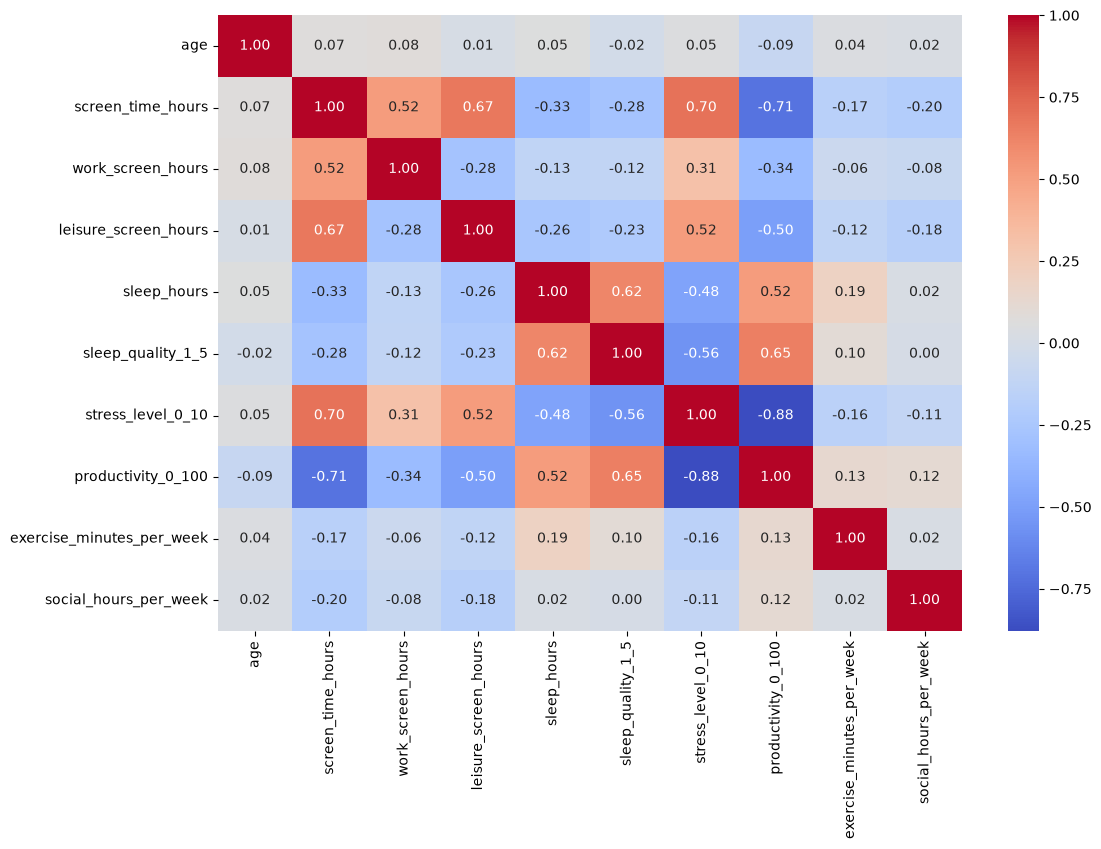

In [230]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.show()

In [236]:
from sklearn.metrics import precision_score, recall_score, f1_score

logprec_score = precision_score(
    y_test, test_pred_value, average='weighted'
)
print(f"The precision score for testing data: {logprec_score*100:.2f}%")

logre_score = recall_score(
    y_test, test_pred_value, average='weighted'
)
print(f"The recall score for testing data: {logre_score*100:.2f}%")

logf1_score = f1_score(
    y_test, test_pred_value, average='weighted'
)
print(f"The F1 score for testing data: {logf1_score*100:.2f}%")

The precision score for testing data: 73.58%
The recall score for testing data: 72.50%
The F1 score for testing data: 72.85%


In [ ]:
import pickle 
with open('mhPred_model.pkl', 'wb') as f:
    pickle.dump(log_model, f)

In [239]:
with open('mhPred_model.pkl', 'rb') as f:
    loaded_lr_model = pickle.load(f)

In [240]:
import sklearn
print(sklearn.__version__)

1.9.1
